Use this notebook to answer four questions:
1. How much does each security control reduce NovaFlow's expected annual cyber loss?
2. How much residual risk remains after implementing each control?
3. Are the expected financial benefits greater than the annual control costs?
4. How do results change under low, central, and high effectiveness assumptions?

We'll do this in two stages: first establish the baseline and individual-control results, then analyze combinations and sensitivity.

Notebook structure
1. Setup:	                    Import modules and configure notebook
2. Control assumptions:	        Display controls, effectiveness, and annual costs
3. Baseline simulation:	        Establish reference AAL and risk metrics
4. Individual controls:	        Simulate each control independently
5. Financial comparison:	        Calculate risk reduction, net benefit, and ROI
6. Combined controls:	        Evaluate all five controls together
7. Effectiveness sensitivity:	Compare low, central, and high assumptions
8. Visualizations:	            Compare AAL, risk reduction, and costs
9. Conclusions:	                Summarize results and implications for optimization

# Step 8B: Security Control Effectiveness Modeling

**Organization:** NovaFlow  
**Scenario:** Third-party vendor OAuth credential compromise leading to unauthorized Salesforce access and customer-data exfiltration.

### Objectives
- Estimate residual Annual Average Loss (AAL) after implementing security controls.
- Compare the effectiveness of individual controls.
- Calculate expected annual risk reduction and net financial benefits.
- Evaluate combined investments and uncertainty in control effectiveness.

All control-effectiveness and cost assumptions are illustrative.

In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.model_config import get_config

from src.control_effectiveness import (
    CONTROL_ASSUMPTIONS,
    make_control_config,
    expected_lef,
    evaluate_controls,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Project root:", PROJECT_ROOT)
print("Controls available:", len(CONTROL_ASSUMPTIONS))


Project root: /Users/shreyagokhale/Desktop/Docs/Documents/Research projects_cybersecurity/novaflow-fair-crq
Controls available: 5


In [ ]:
#Inspect the five controls
#Add a Markdown cell explaining that each control modifies a specific risk mechanism and that effectiveness assumptions are provisional.


# Display the exact control assumptions currently used
# by the Python implementation.

for control_id, assumptions in CONTROL_ASSUMPTIONS.items():
    print(f"\n{control_id}")
    print("-" * 55)
    print(assumptions)

#This lets us confirm that the implementation matches the Step 8A documentation before running simulations.


C1_oauth_governance
-------------------------------------------------------
{'parameter': 'success', 'low': 0.1, 'central': 0.2, 'high': 0.35, 'annual_cost_usd': 75000}

C2_least_privilege
-------------------------------------------------------
{'parameter': 'exposure', 'low': 0.1, 'central': 0.25, 'high': 0.4, 'annual_cost_usd': 90000}

C3_saas_detection
-------------------------------------------------------
{'parameter': 'success', 'low': 0.05, 'central': 0.15, 'high': 0.3, 'annual_cost_usd': 120000}

C4_data_protection
-------------------------------------------------------
{'parameter': 'exposure', 'low': 0.1, 'central': 0.2, 'high': 0.35, 'annual_cost_usd': 110000}

C5_ir_readiness
-------------------------------------------------------
{'parameter': 'response', 'low': 0.1, 'central': 0.2, 'high': 0.3, 'annual_cost_usd': 50000}


In [3]:
#Baseline and individual control simulations

#We'll simulate 20,000 successful incidents per scenario to estimate mean incident loss, then combine that estimate with the scenario's expected annual incident frequency.

#Using the same seed across scenarios helps make comparisons more stable, although it does not guarantee perfectly paired incident draws.



N_INCIDENTS = 20_000
SEED = 20261112

control_ids = list(CONTROL_ASSUMPTIONS)

scenarios = {
    "Baseline": [],
    **{
        control_id: [control_id]
        for control_id in control_ids
    },
    "All five controls": control_ids,
}

rows = []

for scenario_name, controls in scenarios.items():
    print("Simulating:", scenario_name)

    result = evaluate_controls(
        controls=controls,
        level="central",
        n_incidents=N_INCIDENTS,
        seed=SEED,
    )

    rows.append({
        "scenario": scenario_name,
        **result,
    })

results = pd.DataFrame(rows)

display(results)


Simulating: Baseline
Simulating: C1_oauth_governance
Simulating: C2_least_privilege
Simulating: C3_saas_detection
Simulating: C4_data_protection
Simulating: C5_ir_readiness
Simulating: All five controls


,scenario,controls,level,expected_lef,mean_incident_loss_usd,aal_usd,annual_control_cost_usd
0,Baseline,Baseline,central,0.22,"1,223,221.15","272,950.17",0.00
1,C1_oauth_governance,C1_oauth_governance,central,0.18,"1,223,221.15","218,360.14","75,000.00"
2,C2_least_privilege,C2_least_privilege,central,0.22,"1,075,162.68","239,912.33","90,000.00"
3,C3_saas_detection,C3_saas_detection,central,0.19,"1,223,221.15","232,007.65","120,000.00"
4,C4_data_protection,C4_data_protection,central,0.22,"1,103,357.68","246,203.78","110,000.00"
5,C5_ir_readiness,C5_ir_readiness,central,0.22,"1,211,798.81","270,401.39","50,000.00"
6,All five controls,"C1_oauth_governance, C2_least_privilege, C3_sa...",central,0.15,"973,440.93","147,705.58","445,000.00"


In [4]:
#Calculate financial benefits

## We define:

Gross Annual Benefit = Baseline AAL - Residual AAL

Net Annual Benefit = Gross Annual Benefit - Annual Control Cost

ROI = Net Annual Benefit / Annual Control Cost

Here ROI is a one-year, expected-loss-reduction-based return, not a comprehensive business ROI.

In [5]:

baseline_aal = results.loc[
    results["scenario"] == "Baseline",
    "aal_usd",
].iloc[0]

results["gross_risk_reduction_usd"] = (
    baseline_aal - results["aal_usd"]
)

results["risk_reduction_pct"] = (
    100 * results["gross_risk_reduction_usd"]
    / baseline_aal
)

results["net_annual_benefit_usd"] = (
    results["gross_risk_reduction_usd"]
    - results["annual_control_cost_usd"]
)

results["roi_pct"] = np.where(
    results["annual_control_cost_usd"] > 0,
    100 * results["net_annual_benefit_usd"]
    / results["annual_control_cost_usd"].replace(0, np.nan),
    np.nan,
)

display(
    results[
        [
            "scenario",
            "aal_usd",
            "annual_control_cost_usd",
            "gross_risk_reduction_usd",
            "risk_reduction_pct",
            "net_annual_benefit_usd",
            "roi_pct",
        ]
    ].round(2)
)


,scenario,aal_usd,annual_control_cost_usd,gross_risk_reduction_usd,risk_reduction_pct,net_annual_benefit_usd,roi_pct
0,Baseline,"272,950.17",0.00,0.00,0.00,0.00,NaN
1,C1_oauth_governance,"218,360.14","75,000.00","54,590.03",20.00,"-20,409.97",-27.21
2,C2_least_privilege,"239,912.33","90,000.00","33,037.84",12.10,"-56,962.16",-63.29
3,C3_saas_detection,"232,007.65","120,000.00","40,942.53",15.00,"-79,057.47",-65.88
4,C4_data_protection,"246,203.78","110,000.00","26,746.39",9.80,"-83,253.61",-75.69
5,C5_ir_readiness,"270,401.39","50,000.00","2,548.79",0.93,"-47,451.21",-94.90
6,All five controls,"147,705.58","445,000.00","125,244.59",45.89,"-319,755.41",-71.86


## Control Cost Sensitivity Analysis

Control implementation costs are uncertain and depend on existing
security infrastructure, licensing, and staffing.

We evaluate three illustrative incremental annual cost scenarios:
- Low: Existing tools and staff can implement most improvements.
- Central: Moderate incremental licensing, labor, and implementation.
- High: Enterprise-scale implementation (original assumptions).

These are planning assumptions, not verified vendor quotes.

In [6]:

# Annual incremental control costs (USD)
# Illustrative assumptions, not vendor quotes.

CONTROL_COST_SCENARIOS = {
    "C1_oauth_governance": {
        "low": 15000,
        "central": 30000,
        "high": 75000,
    },
    "C2_least_privilege": {
        "low": 20000,
        "central": 35000,
        "high": 90000,
    },
    "C3_saas_detection": {
        "low": 30000,
        "central": 60000,
        "high": 120000,
    },
    "C4_data_protection": {
        "low": 25000,
        "central": 50000,
        "high": 110000,
    },
    "C5_ir_readiness": {
        "low": 10000,
        "central": 25000,
        "high": 50000,
    },
}

cost_rows = []

for _, row in results.iterrows():
    scenario = row["scenario"]

    for cost_level in ["low", "central", "high"]:

        if scenario == "Baseline":
            annual_cost = 0

        elif scenario == "All five controls":
            annual_cost = sum(
                CONTROL_COST_SCENARIOS[c][cost_level]
                for c in control_ids
            )

        else:
            annual_cost = (
                CONTROL_COST_SCENARIOS[scenario][cost_level]
            )

        gross_benefit = row["gross_risk_reduction_usd"]
        net_benefit = gross_benefit - annual_cost

        roi = (
            100 * net_benefit / annual_cost
            if annual_cost > 0
            else np.nan
        )

        cost_rows.append({
            "scenario": scenario,
            "cost_level": cost_level,
            "residual_aal_usd": row["aal_usd"],
            "gross_risk_reduction_usd": gross_benefit,
            "annual_control_cost_usd": annual_cost,
            "net_annual_benefit_usd": net_benefit,
            "roi_pct": roi,
        })

cost_sensitivity = pd.DataFrame(cost_rows)

display(
    cost_sensitivity.round(2)
)


,scenario,cost_level,residual_aal_usd,gross_risk_reduction_usd,annual_control_cost_usd,net_annual_benefit_usd,roi_pct
0,Baseline,low,"272,950.17",0.00,0,0.00,NaN
1,Baseline,central,"272,950.17",0.00,0,0.00,NaN
2,Baseline,high,"272,950.17",0.00,0,0.00,NaN
3,C1_oauth_governance,low,"218,360.14","54,590.03",15000,"39,590.03",263.93
4,C1_oauth_governance,central,"218,360.14","54,590.03",30000,"24,590.03",81.97
5,C1_oauth_governance,high,"218,360.14","54,590.03",75000,"-20,409.97",-27.21
6,C2_least_privilege,low,"239,912.33","33,037.84",20000,"13,037.84",65.19
7,C2_least_privilege,central,"239,912.33","33,037.84",35000,"-1,962.16",-5.61
8,C2_least_privilege,high,"239,912.33","33,037.84",90000,"-56,962.16",-63.29
9,C3_saas_detection,low,"232,007.65","40,942.53",30000,"10,942.53",36.48


In [7]:

# Compare net annual benefits under each cost assumption.

net_benefit_comparison = cost_sensitivity.pivot(
    index="scenario",
    columns="cost_level",
    values="net_annual_benefit_usd",
)

net_benefit_comparison = net_benefit_comparison[
    ["low", "central", "high"]
]

display(
    net_benefit_comparison.style.format("${:,.0f}")
)


cost_level,low,central,high
scenario,,,
All five controls,"$25,245","$-74,755","$-319,755"
Baseline,$0,$0,$0
C1_oauth_governance,"$39,590","$24,590","$-20,410"
C2_least_privilege,"$13,038","$-1,962","$-56,962"
C3_saas_detection,"$10,943","$-19,057","$-79,057"
C4_data_protection,"$1,746","$-23,254","$-83,254"
C5_ir_readiness,"$-7,451","$-22,451","$-47,451"


C1 has a positive net benefit under the low and central cost assumptions, while the other controls become less attractive as costs increase.

## Effectiveness Sensitivity Analysis

In [ ]:

# Low, central, and high control effectiveness.
# Reuse the central simulations already completed.

effectiveness_rows = []

for level in ["low", "central", "high"]:
    for control_id in control_ids:

        if level == "central":
            row = results.loc[
                results["scenario"] == control_id
            ].iloc[0]

            residual_aal = row["aal_usd"]

        else:
            outcome = evaluate_controls(
                controls=[control_id],
                level=level,
                n_incidents=20000,
                seed=20261112,
            )
            residual_aal = outcome["aal_usd"]

        gross_reduction = baseline_aal - residual_aal

        effectiveness_rows.append({
            "control": control_id,
            "effectiveness": level,
            "residual_aal_usd": residual_aal,
            "gross_risk_reduction_usd": gross_reduction,
            "risk_reduction_pct": (
                100 * gross_reduction / baseline_aal
            ),
        })

effectiveness_df = pd.DataFrame(effectiveness_rows)

display(
    effectiveness_df.pivot(
        index="control",
        columns="effectiveness",
        values="gross_risk_reduction_usd",
    )[["low", "central", "high"]].style.format("${:,.0f}")
)

#Expected: Risk reduction should generally increase from low to high effectiveness. Small deviations can occur because of simulation noise.


effectiveness,low,central,high
control,,,
C1_oauth_governance,"$27,295","$54,590","$95,533"
C2_least_privilege,"$12,124","$33,038","$53,187"
C3_saas_detection,"$13,648","$40,943","$81,885"
C4_data_protection,"$12,124","$26,746","$46,242"
C5_ir_readiness,"$1,274","$2,549","$3,823"


In [9]:
#Combined cost and effectiveness sensitivity

#This cell combines all three cost assumptions with all three effectiveness assumptions, creating nine scenarios per control.


financial_rows = []

for _, row in effectiveness_df.iterrows():

    control = row["control"]
    effectiveness = row["effectiveness"]
    gross_benefit = row["gross_risk_reduction_usd"]

    for cost_level in ["low", "central", "high"]:

        annual_cost = CONTROL_COST_SCENARIOS[
            control
        ][cost_level]

        net_benefit = gross_benefit - annual_cost

        financial_rows.append({
            "control": control,
            "effectiveness": effectiveness,
            "cost_level": cost_level,
            "gross_benefit_usd": gross_benefit,
            "annual_cost_usd": annual_cost,
            "net_benefit_usd": net_benefit,
            "roi_pct": 100 * net_benefit / annual_cost,
        })

financial_sensitivity = pd.DataFrame(financial_rows)

# Main decision case:
# Central effectiveness and central implementation cost.

central_financial = financial_sensitivity[
    (financial_sensitivity["effectiveness"] == "central")
    & (financial_sensitivity["cost_level"] == "central")
].copy()

central_financial = central_financial.sort_values(
    "net_benefit_usd",
    ascending=False,
)

display(
    central_financial[
        [
            "control",
            "gross_benefit_usd",
            "annual_cost_usd",
            "net_benefit_usd",
            "roi_pct",
        ]
    ].style.format({
        "gross_benefit_usd": "${:,.0f}",
        "annual_cost_usd": "${:,.0f}",
        "net_benefit_usd": "${:,.0f}",
        "roi_pct": "{:.1f}%",
    })
)

# Full 3x3 financial sensitivity for each control
for control in control_ids:
    print("\n", control)

    subset = financial_sensitivity[
        financial_sensitivity["control"] == control
    ]

    display(
        subset.pivot(
            index="effectiveness",
            columns="cost_level",
            values="net_benefit_usd",
        ).reindex(
            index=["low", "central", "high"],
            columns=["low", "central", "high"],
        ).style.format("${:,.0f}")
    )


,control,gross_benefit_usd,annual_cost_usd,net_benefit_usd,roi_pct
16,C1_oauth_governance,"$54,590","$30,000","$24,590",82.0%
19,C2_least_privilege,"$33,038","$35,000","$-1,962",-5.6%
22,C3_saas_detection,"$40,943","$60,000","$-19,057",-31.8%
28,C5_ir_readiness,"$2,549","$25,000","$-22,451",-89.8%
25,C4_data_protection,"$26,746","$50,000","$-23,254",-46.5%



 C1_oauth_governance


cost_level,low,central,high
effectiveness,,,
low,"$12,295","$-2,705","$-47,705"
central,"$39,590","$24,590","$-20,410"
high,"$80,533","$65,533","$20,533"



 C2_least_privilege


cost_level,low,central,high
effectiveness,,,
low,"$-7,876","$-22,876","$-77,876"
central,"$13,038","$-1,962","$-56,962"
high,"$33,187","$18,187","$-36,813"



 C3_saas_detection


cost_level,low,central,high
effectiveness,,,
low,"$-16,352","$-46,352","$-106,352"
central,"$10,943","$-19,057","$-79,057"
high,"$51,885","$21,885","$-38,115"



 C4_data_protection


cost_level,low,central,high
effectiveness,,,
low,"$-12,876","$-37,876","$-97,876"
central,"$1,746","$-23,254","$-83,254"
high,"$21,242","$-3,758","$-63,758"



 C5_ir_readiness


cost_level,low,central,high
effectiveness,,,
low,"$-8,726","$-23,726","$-48,726"
central,"$-7,451","$-22,451","$-47,451"
high,"$-6,177","$-21,177","$-46,177"


In [10]:
#Combined controls: effectiveness sensitivity

#We already simulated all five controls together under central effectiveness. Let's compare the low and high cases.


combined_rows = []

for level in ["low", "central", "high"]:

    if level == "central":
        residual_aal = results.loc[
            results["scenario"] == "All five controls",
            "aal_usd",
        ].iloc[0]

    else:
        outcome = evaluate_controls(
            controls=control_ids,
            level=level,
            n_incidents=20000,
            seed=20261112,
        )
        residual_aal = outcome["aal_usd"]

    gross_benefit = baseline_aal - residual_aal

    for cost_level in ["low", "central", "high"]:

        annual_cost = sum(
            CONTROL_COST_SCENARIOS[c][cost_level]
            for c in control_ids
        )

        combined_rows.append({
            "effectiveness": level,
            "cost_level": cost_level,
            "residual_aal_usd": residual_aal,
            "gross_benefit_usd": gross_benefit,
            "annual_cost_usd": annual_cost,
            "net_benefit_usd": gross_benefit - annual_cost,
        })

combined_sensitivity = pd.DataFrame(combined_rows)

display(
    combined_sensitivity.pivot(
        index="effectiveness",
        columns="cost_level",
        values="net_benefit_usd",
    ).reindex(
        index=["low", "central", "high"],
        columns=["low", "central", "high"],
    ).style.format("${:,.0f}")
)



cost_level,low,central,high
effectiveness,,,
low,"$-38,190","$-138,190","$-383,190"
central,"$25,245","$-74,755","$-319,755"
high,"$86,629","$-13,371","$-258,371"


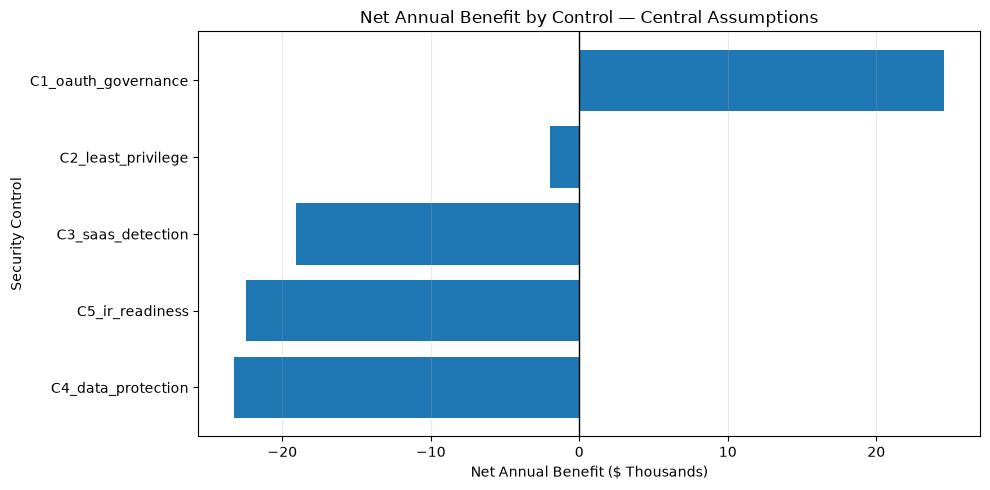

In [11]:
#Final visualization
fig, ax = plt.subplots(figsize=(10, 5))

plot_df = central_financial.sort_values(
    "net_benefit_usd"
)

ax.barh(
    plot_df["control"],
    plot_df["net_benefit_usd"] / 1000,
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    "Net Annual Benefit by Control — Central Assumptions"
)
ax.set_xlabel("Net Annual Benefit ($ Thousands)")
ax.set_ylabel("Security Control")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


In [12]:

output_dir = PROJECT_ROOT / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(
    output_dir / "control_effectiveness_baseline.csv",
    index=False,
)

cost_sensitivity.to_csv(
    output_dir / "control_cost_sensitivity.csv",
    index=False,
)

effectiveness_df.to_csv(
    output_dir / "control_effectiveness_sensitivity.csv",
    index=False,
)

financial_sensitivity.to_csv(
    output_dir / "control_financial_sensitivity.csv",
    index=False,
)

combined_sensitivity.to_csv(
    output_dir / "combined_controls_sensitivity.csv",
    index=False,
)

print("STEP 8B COMPLETE")
print("=" * 50)

print(f"Baseline AAL: ${baseline_aal:,.0f}")

print("\nCentral-case financial ranking:")
for _, row in central_financial.iterrows():
    print(
        f"{row['control']}: "
        f"net benefit ${row['net_benefit_usd']:,.0f}"
    )

print("\nSaved five result tables to outputs/")

print(
    "\nLimitations: Illustrative effectiveness and "
    "cost assumptions; single attack scenario; "
    "AAL only, not VaR/TVaR."
)


STEP 8B COMPLETE
Baseline AAL: $272,950

Central-case financial ranking:
C1_oauth_governance: net benefit $24,590
C2_least_privilege: net benefit $-1,962
C3_saas_detection: net benefit $-19,057
C5_ir_readiness: net benefit $-22,451
C4_data_protection: net benefit $-23,254

Saved five result tables to outputs/

Limitations: Illustrative effectiveness and cost assumptions; single attack scenario; AAL only, not VaR/TVaR.
